<span style="font-size:2em;">Instructor: Dr. Qipei (Gavin) Mei (qipei.mei@ualberta.ca); Yuezhen Gao (yuezhen@ualberta.ca)</span>

<span style="font-size:2em;">Student Name: Amilcar Díaz</span>

<span style="font-size:2em;">CCID: adiazgar</span>

# Question 1: Predicción de la resistencia a compresión del concreto con una red neuronal [30 Marks]

## 1. Configuración

En esta sección se cargan las librerias y fijan los parámetros que se utilizarán en el notebook.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap, LogNorm
from sklearn.model_selection import KFold, cross_validate
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from scipy import stats

TRAIN_VAL_FILE = Path(".") / "train-val.csv"
TEST_FILE = Path(".") / "test.csv"

# Features in the same order as in the dataset
FEATURES = ["cement", "slag", "fly_ash", "water", "superplasticizer",
            "coarse_agg", "fine_agg", "age"]
TARGET = "strength"
COLUMNS = FEATURES + [TARGET]
UNITS = ["kg/m³"] * 7 + ["days", "MPa"]
ROLES = ["input"] * 8 + ["output"]

# Description for each feature
LABELS = {
    "cement": "Cement (kg/m³)",
    "slag": "Blast furnace slag (kg/m³)",
    "fly_ash": "Fly ash (kg/m³)",
    "water": "Water (kg/m³)",
    "superplasticizer": "Superplasticizer (kg/m³)",
    "coarse_agg": "Coarse aggregate (kg/m³)",
    "fine_agg": "Fine aggregate (kg/m³)",
    "age": "Age (days)",
    "strength": "Compressive strength (MPa)",
}

# Number of folds for cross validation
N_FOLDS = 10

# To number the tables automatically
t_num = 0

# Function to display a DataFrame as a table with a caption and optional formatting
def show_table(df, number, caption, precision=2, hide_index=False, n_rows=None):
    display(Markdown(f"**Table {number}.** {caption}"))

    # Truncate table (for long DataFrames)
    if n_rows is not None and len(df) > 2 * n_rows:
        ellipsis_row = pd.DataFrame([["..."] * df.shape[1]], columns=df.columns, index=["..."])
        df = pd.concat([df.head(n_rows), ellipsis_row, df.tail(n_rows)])

    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)

## 2. Análisis del dataset

Primero se leen los datos desde los CSV donde se encuentra el data set de entrenamiento y el dataset de prueba.

In [2]:
train_val_raw = pd.read_csv(TRAIN_VAL_FILE, encoding="utf-8-sig")
test_raw = pd.read_csv(TEST_FILE, encoding="utf-8-sig")

# Changing name of columns (short name)
train_val_df = train_val_raw.set_axis(COLUMNS, axis=1)
test_df = test_raw.set_axis(COLUMNS, axis=1)
#train_val_df.index = pd.RangeIndex(1, len(train_val_df) + 1, name="record")

t_num += 1
show_table(train_val_df, t_num, "Datos de entrenamiento importados.", hide_index=False, n_rows=5)
print(f"train-val: {train_val_df.shape[0]} samples, {train_val_df.shape[1]} columns")

t_num += 1
show_table(test_df, t_num, "Datos de prueba importados.", hide_index=False, n_rows=5)
print(f"test:      {test_df.shape[0]} samples, {test_df.shape[1]} columns")


**Table 1.** Datos de entrenamiento importados.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,299.80,0.00,119.80,211.50,9.90,878.20,727.60,28,23.84
1,213.70,0.00,174.70,154.80,10.20,1053.50,776.40,56,46.64
2,202.00,11.00,141.00,206.00,1.70,942.00,801.00,56,23.25
3,446.00,24.00,79.00,162.00,11.60,967.00,712.00,56,56.14
4,277.00,0.00,0.00,191.00,0.00,968.00,856.00,90,31.25
...,...,...,...,...,...,...,...,...,...
819,275.10,0.00,121.40,159.50,9.90,1053.60,777.50,14,38.77
820,148.10,0.00,136.60,158.10,16.10,1001.80,830.10,28,17.96
821,190.00,190.00,0.00,228.00,0.00,932.00,670.00,365,53.69
822,356.00,0.00,142.00,193.00,11.00,801.00,778.00,28,40.87


train-val: 824 samples, 9 columns


**Table 2.** Datos de prueba importados.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,321.40,0.00,127.90,182.50,11.50,870.10,779.70,28,37.27
1,249.10,0.00,98.80,158.10,12.80,987.80,889.00,100,51.06
2,167.40,129.90,128.60,175.50,7.80,1006.30,746.60,100,53.66
3,251.80,0.00,99.90,146.10,12.40,1006.00,899.80,56,44.14
4,116.00,173.00,0.00,192.00,0.00,909.80,891.90,90,31.02
...,...,...,...,...,...,...,...,...,...
201,145.00,116.00,119.00,184.00,5.70,833.00,880.00,28,29.16
202,531.30,0.00,0.00,141.80,28.20,852.10,893.70,91,59.20
203,302.00,0.00,0.00,203.00,0.00,974.00,817.00,28,21.75
204,491.00,26.00,123.00,210.00,3.90,882.00,699.00,56,59.59


test:      206 samples, 9 columns


Verificación si los DataFrames tienen datos faltantes.

In [3]:
print(f"Datos faltantes en el set de entrenamiento: {train_val_df.isna().sum().sum()}")
print(f"Datos faltantes en el set de prueba: {test_df.isna().sum().sum()}")

Datos faltantes en el set de entrenamiento: 0
Datos faltantes en el set de prueba: 0


Verificación si hay registros repetidos (mismos features and outputs)

In [4]:
train_val_dups = train_val_df[train_val_df.duplicated(keep=False)].sort_values(by=list(train_val_df.columns))

dups = train_val_dups.groupby(list(train_val_df.columns)).size().reset_index(name="count")

t_num += 1
show_table(dups, t_num, "Registros repetidos en el set de entrenamiento y validación.", hide_index=True)

print(f"Se encontraron {len(train_val_dups)} registros duplicados en el set de entrenamiento y validación ({len(train_val_dups)-len(dups)} copias de {len(dups)} registros distintos).")

**Table 3.** Registros repetidos en el set de entrenamiento y validación.

cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,count
252.00,0.00,0.00,185.00,0.00,1111.00,784.00,28,19.69,2
362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30,3
362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90,3
362.60,189.00,0.00,164.90,11.60,944.70,755.80,28,71.30,2
362.60,189.00,0.00,164.90,11.60,944.70,755.80,56,77.30,4
362.60,189.00,0.00,164.90,11.60,944.70,755.80,91,79.30,4
425.00,106.30,0.00,153.50,16.50,852.10,887.10,3,33.40,3
425.00,106.30,0.00,153.50,16.50,852.10,887.10,7,49.20,2
425.00,106.30,0.00,153.50,16.50,852.10,887.10,28,60.29,3
425.00,106.30,0.00,153.50,16.50,852.10,887.10,56,64.30,2


Se encontraron 30 registros duplicados en el set de entrenamiento y validación (19 copias de 11 registros distintos).


Para evitar que en la validación cruzada un mismo registro quede en el set de entrenamiento y a la vez tambien quede en el set de validación, se decide eliminar los registros duplicados.

In [5]:
train_val_df = train_val_df.drop_duplicates()

t_num += 1
show_table(train_val_df, t_num, "Datos de entrenamiento y validacion sin duplicados.", hide_index=False, n_rows=5)
print(f"train-val: {train_val_df.shape[0]} samples, {train_val_df.shape[1]} columns")

**Table 4.** Datos de entrenamiento y validacion sin duplicados.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,299.80,0.00,119.80,211.50,9.90,878.20,727.60,28,23.84
1,213.70,0.00,174.70,154.80,10.20,1053.50,776.40,56,46.64
2,202.00,11.00,141.00,206.00,1.70,942.00,801.00,56,23.25
3,446.00,24.00,79.00,162.00,11.60,967.00,712.00,56,56.14
4,277.00,0.00,0.00,191.00,0.00,968.00,856.00,90,31.25
...,...,...,...,...,...,...,...,...,...
819,275.10,0.00,121.40,159.50,9.90,1053.60,777.50,14,38.77
820,148.10,0.00,136.60,158.10,16.10,1001.80,830.10,28,17.96
821,190.00,190.00,0.00,228.00,0.00,932.00,670.00,365,53.69
822,356.00,0.00,142.00,193.00,11.00,801.00,778.00,28,40.87


train-val: 805 samples, 9 columns


Verificamos si una misma mezcla produce la diferente resistencia a la misma edad.

In [6]:
repeated_mixes = (train_val_df.groupby(FEATURES)[TARGET].agg(n_samples="count", min_strength="min", max_strength="max").query("n_samples > 1"))
repeated_mixes["difference"] = repeated_mixes["max_strength"] - repeated_mixes["min_strength"]

t_num += 1
show_table(repeated_mixes.reset_index(), t_num, "Grupos de muestras de train-val con las mismas entradas (mezcla y edad) pero distinta resistencia.", hide_index=True)

**Table 5.** Grupos de muestras de train-val con las mismas entradas (mezcla y edad) pero distinta resistencia.

cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,n_samples,min_strength,max_strength,difference
359.00,19.00,141.00,154.00,10.90,942.00,801.00,28,2,59.49,62.94,3.45
359.00,19.00,141.00,154.00,10.90,942.00,801.00,56,2,66.78,68.75,1.97
362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,2,22.90,55.90,33.00
446.00,24.00,79.00,162.00,11.60,967.00,712.00,3,2,23.35,25.02,1.67
446.00,24.00,79.00,162.00,11.60,967.00,712.00,7,3,38.02,52.01,13.99
446.00,24.00,79.00,162.00,11.60,967.00,712.00,28,3,44.42,57.03,12.61
446.00,24.00,79.00,162.00,11.60,967.00,712.00,56,2,56.14,61.07,4.93


En la tabla 5 se observan algunos valores con diferencias en la resistencia a la compresión fuera de lo esperado. Sin embargo, en esta etapa no se toma ninguna decisión por que no se cuenta con información necesaria para validar un resultado y descartar otro o descartar ambos. (mejorar esta redacción).

De acuerdo a Yeh (1998), una red neuronal no extrapola bien fuera del dominio de los datos para lo que se entrenó. Se verifica si algún feature del set de prueba está fuera de los rangos del set de entrenamiento y validación.

In [7]:
train_min = train_val_df[FEATURES].min()
train_max = train_val_df[FEATURES].max()

below_range = test_df[FEATURES] < train_min
above_range = test_df[FEATURES] > train_max

outside = pd.DataFrame({"train-val min": train_min, "train-val max": train_max, "test samples outside range": (below_range | above_range).sum()})

filtered = (below_range | above_range).any(axis=1)

samples_outside = test_df[filtered]

t_num += 1
show_table(outside, t_num, "Verificación de muestras de prueba fuera de los rangos de las muestras de entrenamiento y validación.", hide_index=True)
t_num += 1
show_table(samples_outside, t_num, "Muestras con al menos un feature fuera de rango.", hide_index=False)

**Table 6.** Verificación de muestras de prueba fuera de los rangos de las muestras de entrenamiento y validación.

train-val min,train-val max,test samples outside range
102.00,540.00,0
0.00,359.40,0
0.00,200.10,0
121.80,246.90,1
0.00,32.20,0
801.00,1145.00,0
594.00,992.60,0
1.00,365.00,0


**Table 7.** Muestras con al menos un feature fuera de rango.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
18,237.00,92.00,71.00,247.00,6.00,853.00,695.00,28,28.63


Las tablas 6 y 7 muestran que solamente una muestra del set de prueba tiene features fuera de los rangos del set de entrenamiento y validación. Se mantiene la muestra en el set de prueba y al final se verifica el rendimiento del modelo en esta extrapolación.

## Construcción del modelo

In [8]:
# Features and target
X = train_val_df.iloc[:, :8]
y = train_val_df.iloc[:, -1]

# Pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32),
                         alpha=1e0,
                         activation="relu",
                         max_iter=2000,
                         early_stopping=True,
                         random_state=42)),
])

# Cross-validation
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

# Accumulates results from all blocks
all_results = []

def evaluate_models(models, X, y, early_stopping=True, n_iter_no_change=10,
                    validation_fraction=0.1, tol=1e-4, max_iter=2000):

    # Stopping rules for this call (a model can override them in its own dict)
    stopping = {"early_stopping": early_stopping,
                "n_iter_no_change": n_iter_no_change,
                "validation_fraction": validation_fraction,
                "tol": tol,
                "max_iter": max_iter}

    rows = []
    for m in models:
        params = {**stopping, **m}

        # Model with this configuration
        est = clone(model).set_params(**{f"mlp__{k}": v for k, v in params.items()})
        mlp = est.named_steps["mlp"]

        # Cross-validation, keeping the fitted model of each fold
        cv = cross_validate(est, X, y, cv=kf,
                            scoring="neg_root_mean_squared_error",
                            return_train_score=True,
                            return_estimator=True)

        # Epochs actually run in each fold and the reason each fold stopped
        epochs = np.array([e.named_steps["mlp"].n_iter_ for e in cv["estimator"]])
        rule = "validation" if mlp.early_stopping else "training loss plateau"
        reasons = pd.Series(np.where(epochs < mlp.max_iter, rule, "max_iter")).value_counts()
        stop_rule = ", ".join(f"{r} ({c})" for r, c in reasons.items())

        rmse_train = -cv["train_score"]
        rmse_val = -cv["test_score"]

        rows.append({
            # Model configuration
            "layers": mlp.hidden_layer_sizes,
            "alpha": mlp.alpha,
            "activation": mlp.activation,
            # Model quality
            "RMSE train": rmse_train.mean(),
            "RMSE train std": rmse_train.std(),
            "CoV train (%)": rmse_train.std() / rmse_train.mean() * 100,
            "RMSE val": rmse_val.mean(),
            "RMSE val std": rmse_val.std(),
            "CoV val (%)": rmse_val.std() / rmse_val.mean() * 100,
            "RMSE gap (MPa)": rmse_val.mean() - rmse_train.mean(),
            "RMSE ratio": rmse_val.mean() / rmse_train.mean(),
            # Training process
            "epochs (mean)": epochs.mean(),
            "stop rule (folds)": stop_rule,
            "fit time (s)": cv["fit_time"].mean(),
        })

    # Lower RMSE is better
    results = pd.DataFrame(rows).sort_values("RMSE val").reset_index(drop=True)

    all_results.append(results)
    return results



Se verifica el performance de diferentes redes de 1 capa con diferente cantidades de neuronas.

In [9]:
models_1_layer = [
    {"hidden_layer_sizes": (16,), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (32,), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (64,), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (128,), "alpha": 1, "activation": "relu"},
    #{"hidden_layer_sizes": (256,), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (16,), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (32,), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (64,), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (128,), "alpha": 1, "activation": "tanh"},
    #{"hidden_layer_sizes": (256,), "alpha": 1, "activation": "tanh"}

]

comparison = {}

comparison["1 layer"] = evaluate_models(models_1_layer, X, y,
                                        early_stopping=True,
                                        n_iter_no_change=10,
                                        validation_fraction=0.1,
                                        tol=1e-4,
                                        max_iter=2000)



In [10]:
t_num += 1
t_name = "Comparación del rendimiento de modelos de 1 capa con diferentes cantidades de neuronas."
show_table(comparison["1 layer"], t_num,  t_name, precision=4, hide_index=True)

**Table 8.** Comparación del rendimiento de modelos de 1 capa con diferentes cantidades de neuronas.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(128,)",1,relu,6.2486,0.2586,4.1380,6.8989,0.9030,13.0884,0.6503,1.1041,589.5000,validation (10),0.6500
"(32,)",1,tanh,6.7586,0.4908,7.2622,7.0941,1.0780,15.1957,0.3355,1.0496,873.8000,validation (10),0.6260
"(64,)",1,tanh,6.8581,0.3588,5.2314,7.1010,0.8976,12.6403,0.2429,1.0354,557.6000,validation (10),0.6045
"(128,)",1,tanh,6.9645,0.2539,3.6461,7.1567,0.8643,12.0772,0.1922,1.0276,403.3000,validation (10),0.7077
"(32,)",1,relu,6.6144,0.5580,8.4368,7.1696,0.8913,12.4316,0.5552,1.0839,957.3000,validation (10),0.6315
"(64,)",1,relu,6.5154,0.5744,8.8162,7.3006,1.0185,13.9510,0.7852,1.1205,825.0000,validation (10),0.6741
"(16,)",1,tanh,7.0571,0.6301,8.9292,7.4422,1.1352,15.2539,0.3851,1.0546,1316.7000,validation (10),0.8019
"(16,)",1,relu,7.2165,0.7202,9.9805,7.7519,1.1169,14.4078,0.5354,1.0742,1281.1000,validation (10),0.8292


La red de 1 capa de 256 neuronas es la que tiene el RMSE de validación más bajo pero incrementa el ratio de RMSE (RMSE de validación / RMSE de entrenamiento), lo cual puede significar que el modelo está siendo sobreajustado a los datos de enrtenamiento.

Se analizaran las redes de 1 capa de 128 neuronas y función de activación relu y 32 neuronas con función de activacion tanh para verificar si el modelo puede ser mejorado con otros valores de alpha.

In [11]:
models_1_layer_alphas = [
    # ReLU
    {"hidden_layer_sizes": (128,), "alpha": 0.1, "activation": "relu"},
    {"hidden_layer_sizes": (128,), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (128,), "alpha": 10,  "activation": "relu"},
    {"hidden_layer_sizes": (32,), "alpha": 0.1,   "activation": "tanh"},
    {"hidden_layer_sizes": (32,), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (32,), "alpha": 10,  "activation": "tanh"},]

comparison["1 layer alphas"] = evaluate_models(models_1_layer_alphas, X, y,
                                        early_stopping=True,
                                        n_iter_no_change=10,
                                        validation_fraction=0.1,
                                        tol=1e-4,
                                        max_iter=2000)

In [12]:
t_num += 1
t_name = "Comparación del rendimiento de los modelos de 1 capa con 32 y 128 neuronas, con diferentes valores de alpha."
show_table(comparison["1 layer alphas"], t_num,  t_name, precision=4, hide_index=True)

**Table 9.** Comparación del rendimiento de los modelos de 1 capa con 32 y 128 neuronas, con diferentes valores de alpha.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(128,)",0.1000,relu,6.2201,0.2833,4.5541,6.8915,0.9571,13.8878,0.6715,1.1080,588.6000,validation (10),0.8945
"(128,)",1.0000,relu,6.2486,0.2586,4.1380,6.8989,0.9030,13.0884,0.6503,1.1041,589.5000,validation (10),0.7743
"(128,)",10.0000,relu,6.5161,0.2581,3.9614,7.0670,0.8974,12.6989,0.5509,1.0845,588.4000,validation (10),0.8859
"(32,)",0.1000,tanh,6.7555,0.4711,6.9739,7.0850,1.0656,15.0402,0.3295,1.0488,865.5000,validation (10),0.8188
"(32,)",1.0000,tanh,6.7586,0.4908,7.2622,7.0941,1.0780,15.1957,0.3355,1.0496,873.8000,validation (10),0.6926
"(32,)",10.0000,tanh,7.1148,0.3890,5.4677,7.3656,1.0284,13.9619,0.2508,1.0353,840.2000,validation (10),0.7652


Para los modelos de 1 capa, el de 128 neuronas con función de activación relu parecen ser los modelos que mejor predicen la resistencia a la compresión del concreto. Se elige el de alpha = 1 porque es el más simple y tiene un rendimiento muy similar al del alpha = 0.01.

In [13]:
selected_models = [{"hidden_layer_sizes": (128,), "alpha": 1, "activation": "relu"},
]

Se verifica el performance de los modelos de 2 capas

In [14]:
models_2_layers = [
    {"hidden_layer_sizes": (32, 16), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (64, 32), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (128, 64), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (256, 128), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (32, 16), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (64, 32), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (128, 64), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (256, 128), "alpha": 1, "activation": "tanh"},
]

comparison["2 layers"] = evaluate_models(models_2_layers, X, y,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

In [15]:
t_num += 1
t_name = "Comparación del rendimiento de modelos de 2 capas con diferente cantidades de neuronas."
show_table(comparison["2 layers"], t_num,  t_name, precision=4, hide_index=True)

**Table 10.** Comparación del rendimiento de modelos de 2 capas con diferente cantidades de neuronas.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(128, 64)",1,relu,5.1168,0.6415,12.5371,6.2473,0.8116,12.9913,1.1305,1.2209,304.2000,validation (10),1.1409
"(256, 128)",1,tanh,5.6903,0.4893,8.5985,6.4516,0.9339,14.4754,0.7613,1.1338,293.8000,validation (10),2.5280
"(64, 32)",1,tanh,6.0833,0.7748,12.7369,6.7967,0.9646,14.1915,0.7135,1.1173,783.8000,validation (10),1.2563
"(128, 64)",1,tanh,6.2740,1.1345,18.0822,7.0029,1.0691,15.2663,0.7289,1.1162,450.5000,validation (10),1.8756
"(256, 128)",1,relu,6.3881,2.9674,46.4527,7.1536,2.6598,37.1818,0.7655,1.1198,210.3000,validation (10),1.5775
"(32, 16)",1,tanh,6.7571,1.1174,16.5361,7.3420,1.2579,17.1337,0.5848,1.0865,1243.3000,validation (10),1.3341
"(64, 32)",1,relu,6.8490,2.7251,39.7877,7.6197,2.3671,31.0652,0.7707,1.1125,346.9000,validation (10),0.4694
"(32, 16)",1,relu,8.7646,3.0875,35.2273,9.2771,2.7360,29.4917,0.5126,1.0585,408.1000,validation (10),0.4119


In [16]:
models_2_layers_alphas = [
    {"hidden_layer_sizes": (128, 64), "alpha": 0.1, "activation": "relu"},
    {"hidden_layer_sizes": (128, 64), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (128, 64), "alpha": 10, "activation": "relu"},

    {"hidden_layer_sizes": (256, 128), "alpha": 0.1, "activation": "tanh"},
    {"hidden_layer_sizes": (256, 128), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (256, 128), "alpha": 10, "activation": "tanh"},

    {"hidden_layer_sizes": (64, 32), "alpha": 0.1, "activation": "tanh"},
    {"hidden_layer_sizes": (64, 32), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (64, 32), "alpha": 10, "activation": "tanh"},
    ]

comparison["2 layer alphas"] = evaluate_models(models_2_layers_alphas, X, y,
                                        early_stopping=True,
                                        n_iter_no_change=10,
                                        validation_fraction=0.1,
                                        tol=1e-4,
                                        max_iter=2000)

In [17]:
t_num += 1
t_name = "Comparación del rendimiento de los mejores modelos de 2 capas con diferentes valores de alpha."
show_table(comparison["2 layer alphas"], t_num,  t_name, precision=4, hide_index=True)

**Table 11.** Comparación del rendimiento de los mejores modelos de 2 capas con diferentes valores de alpha.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(128, 64)",1.0000,relu,5.1168,0.6415,12.5371,6.2473,0.8116,12.9913,1.1305,1.2209,304.2000,validation (10),1.0107
"(128, 64)",0.1000,relu,5.2101,0.5980,11.4774,6.2593,0.7670,12.2539,1.0492,1.2014,302.2000,validation (10),1.0113
"(256, 128)",0.1000,tanh,5.5981,0.5237,9.3550,6.4362,0.9672,15.0277,0.8381,1.1497,301.3000,validation (10),2.5078
"(256, 128)",1.0000,tanh,5.6903,0.4893,8.5985,6.4516,0.9339,14.4754,0.7613,1.1338,293.8000,validation (10),2.5175
"(128, 64)",10.0000,relu,5.4732,0.4731,8.6435,6.4532,0.8357,12.9501,0.9800,1.1791,284.4000,validation (10),0.9438
"(256, 128)",10.0000,tanh,6.1306,0.4223,6.8882,6.6429,0.9015,13.5703,0.5124,1.0836,281.2000,validation (10),2.3182
"(64, 32)",1.0000,tanh,6.0833,0.7748,12.7369,6.7967,0.9646,14.1915,0.7135,1.1173,783.8000,validation (10),1.0989
"(64, 32)",0.1000,tanh,6.0625,0.6329,10.4402,6.8108,0.9656,14.1768,0.7483,1.1234,776.9000,validation (10),1.1082
"(64, 32)",10.0000,tanh,6.4468,0.5708,8.8546,6.9091,0.7039,10.1883,0.4623,1.0717,794.9000,validation (10),1.1161


In [18]:
selected_models.append({"hidden_layer_sizes": (128, 64), "alpha": 0.1, "activation": "relu"})
selected_models.append({"hidden_layer_sizes": (128, 64), "alpha": 1, "activation": "relu"})

In [19]:
models_3_layers = [
    {"hidden_layer_sizes": (64, 32, 16), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (128, 64, 32), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (256, 128, 64), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (64, 32, 16), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (128, 64, 32), "alpha": 1, "activation": "tanh"},
    {"hidden_layer_sizes": (256, 128, 64), "alpha": 1, "activation": "tanh"},
]

comparison["3 layers"] = evaluate_models(models_3_layers, X, y,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

In [20]:
t_num += 1
t_name = "Comparación del rendimiento de modelos de 3 capas con diferente cantidades de neuronas."
show_table(comparison["3 layers"], t_num, t_name, hide_index=True)

**Table 12.** Comparación del rendimiento de modelos de 3 capas con diferente cantidades de neuronas.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(256, 128, 64)",1,relu,4.61,0.84,18.15,5.93,0.65,10.88,1.32,1.29,189.70,validation (10),1.57
"(128, 64, 32)",1,relu,5.10,0.42,8.16,6.25,0.78,12.41,1.15,1.23,192.90,validation (10),0.74
"(256, 128, 64)",1,tanh,5.16,0.74,14.28,6.26,1.13,18.05,1.10,1.21,446.10,validation (10),4.43
"(64, 32, 16)",1,relu,5.35,0.47,8.69,6.48,0.64,9.80,1.13,1.21,277.60,validation (10),0.38
"(128, 64, 32)",1,tanh,5.64,1.05,18.71,6.77,1.52,22.40,1.14,1.20,765.70,validation (10),3.81
"(64, 32, 16)",1,tanh,6.43,1.01,15.73,7.43,1.21,16.26,1.00,1.16,1200.30,validation (10),1.96


El modelo `{"hidden_layer_sizes": (256, 128, 64), "alpha": 1, "activation": "relu"}` predice mucho mejor los valores de validación pese a tener una relación RMSE de Validación / RMSE de entrenamiento es 1.29 lo cual podría ser indicio de overfitting. Se verifica si ajustando el alpha mejora su rendimiento.

In [21]:
models_3_layers_alphas = [
    {"hidden_layer_sizes": (256, 128, 64), "alpha": 0.1, "activation": "relu"},
    {"hidden_layer_sizes": (256, 128, 64), "alpha": 1, "activation": "relu"},
    {"hidden_layer_sizes": (256, 128, 64), "alpha": 10, "activation": "relu"}
]

comparison["3 layers alphas"] = evaluate_models(models_3_layers_alphas, X, y,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

In [22]:
t_num += 1
t_name = "Comparación del rendimiento de los mejores modelos de 3 capas con diferentes valores de alpha."
show_table(comparison["3 layers alphas"], t_num,  t_name, precision=4, hide_index=True)

**Table 13.** Comparación del rendimiento de los mejores modelos de 3 capas con diferentes valores de alpha.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(256, 128, 64)",1.0000,relu,4.6081,0.8364,18.1505,5.9288,0.6450,10.8799,1.3207,1.2866,189.7000,validation (10),1.7088
"(256, 128, 64)",10.0000,relu,4.7339,0.6279,13.2639,5.9788,0.7180,12.0098,1.2448,1.2630,185.0000,validation (10),1.5543
"(256, 128, 64)",0.1000,relu,4.6009,0.5932,12.8930,5.9881,0.5424,9.0585,1.3872,1.3015,185.7000,validation (10),1.5653


In [23]:
selected_models.append({"hidden_layer_sizes": (256, 128, 64), "alpha": 1, "activation": "relu"})

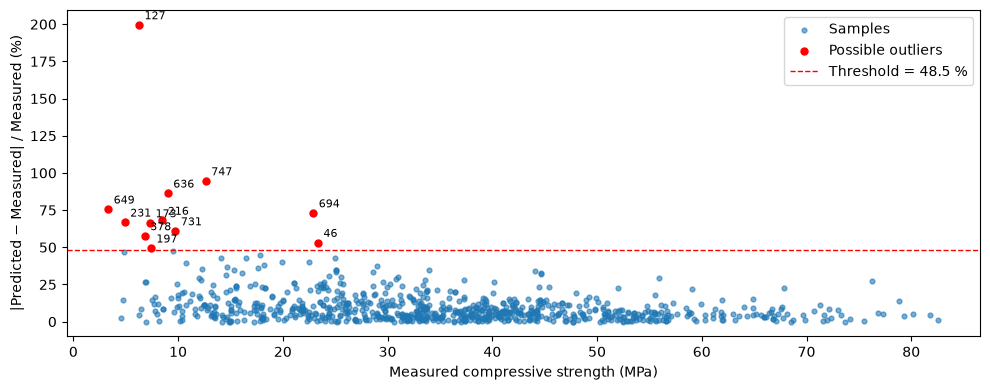

**Table 14.** Possible outliers in the train-validation set.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,rel_error
46,446.00,24.00,79.00,162.00,11.60,967.00,712.00,3,23.35,53.22
127,385.00,0.00,0.00,186.00,0.00,966.00,763.00,1,6.27,199.57
173,182.00,45.20,122.00,170.20,8.20,1059.40,780.70,3,7.32,66.40
197,168.90,42.20,124.30,158.30,10.80,1080.80,796.20,3,7.40,49.48
216,250.00,0.00,95.70,191.80,5.30,948.90,857.20,3,8.49,68.14
231,183.90,122.60,0.00,203.50,0.00,959.20,800.00,3,4.90,66.89
378,212.00,141.30,0.00,203.50,0.00,973.40,750.00,3,6.81,57.70
636,349.00,0.00,0.00,192.00,0.00,1056.00,809.00,7,9.01,86.36
649,122.60,183.90,0.00,203.50,0.00,958.20,800.10,3,3.32,75.65
694,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,22.90,73.12


In [24]:
best_model = clone(model).set_params(mlp__hidden_layer_sizes=(256, 128, 64),
                                     mlp__alpha=1,
                                     mlp__activation="relu")
best_model.fit(X, y)
y_pred = best_model.predict(X)

rel_error = ((y - y_pred).abs() / y) * 100

# Set an approximated threshold of 3 standard devations above the mean of rel_error
threshold = rel_error.mean() + 3 * rel_error.std()

# Boleean of possible outliers
outliers = rel_error > threshold

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(y[~outliers], rel_error[~outliers], s=12, alpha=0.6, label="Samples")
ax.scatter(y[outliers], rel_error[outliers], s=25, color="red", label="Possible outliers")
ax.axhline(threshold, color="red", linestyle="--", linewidth=1, label=f"Threshold = {threshold:.1f} %")

# Label outliers with their index
for idx in rel_error[outliers].index:
    ax.annotate(str(idx), (y[idx], rel_error[idx]),
                textcoords="offset points", xytext=(4, 4), fontsize=8)

ax.set_xlabel("Measured compressive strength (MPa)")
ax.set_ylabel("|Predicted − Measured| / Measured (%)")
ax.legend()
plt.tight_layout()
plt.show()

# Table of possible outliers
t_num += 1
show_table(train_val_df.loc[outliers].assign(rel_error=rel_error[outliers]), t_num, "Possible outliers in the train-validation set.", hide_index=False)


El error de la figura anterior se calcula con el mismo modelo que se entrenó con todos los datos (error de entrenamiento), por lo que el error de los outliers puede quedar subestimado.

La mayoria de los posibles outliers detectados son mezclas con edades de 1, 3 y 7 días. En la siguiente figura se verifica el comportamiento de todas las muestras de esas edades.

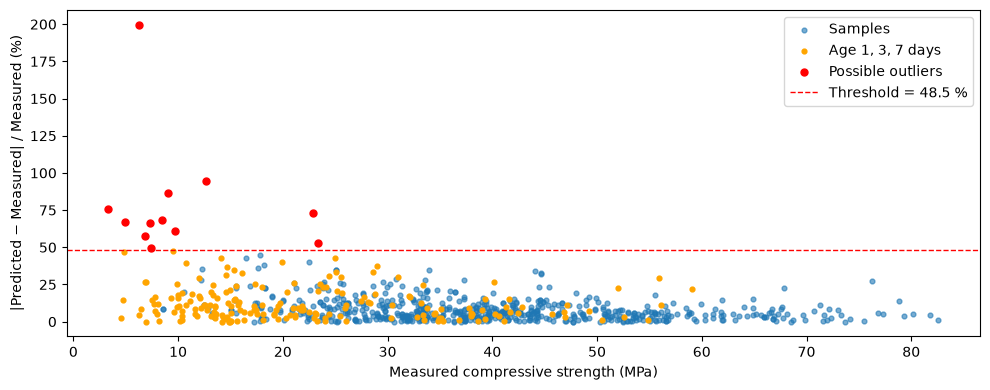

In [25]:
# Samples with age of 1, 3 or 7 days
early_age = train_val_df["age"].isin([1, 3, 7])

fig_age, ax_age = plt.subplots(figsize=(10, 4))
ax_age.scatter(y[~early_age & ~outliers], rel_error[~early_age & ~outliers], s=12, alpha=0.6, label="Samples")
ax_age.scatter(y[early_age & ~outliers], rel_error[early_age & ~outliers], s=12, color="orange", label="Age 1, 3, 7 days")
ax_age.scatter(y[outliers], rel_error[outliers], s=25, color="red", label="Possible outliers")
ax_age.axhline(threshold, color="red", linestyle="--", linewidth=1, label=f"Threshold = {threshold:.1f} %")

ax_age.set_xlabel("Measured compressive strength (MPa)")
ax_age.set_ylabel("|Predicted − Measured| / Measured (%)")
ax_age.legend()
plt.tight_layout()
plt.show()

Se analiza la strength development curve de las mezcla de cada posible outliers para verificar si efectivamente son outliers.

In [26]:
MIX_COLS = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"]

# One DataFrame per outlier with all samples that share its exact mix
mix_groups = {}
for idx in outliers[outliers].index:

    # Mix of the outlier idx
    mix = train_val_df.loc[idx, MIX_COLS]

    # Boolean of same mix
    same_mix = (train_val_df[MIX_COLS] == mix).all(axis=1)
    mix_groups[idx] = (train_val_df[same_mix]
                       .assign(rel_error=rel_error[same_mix],
                               is_outlier=outliers[same_mix])
                       .sort_values("age"))

mix_groups_df = pd.concat(mix_groups, names=["outlier", "sample"])



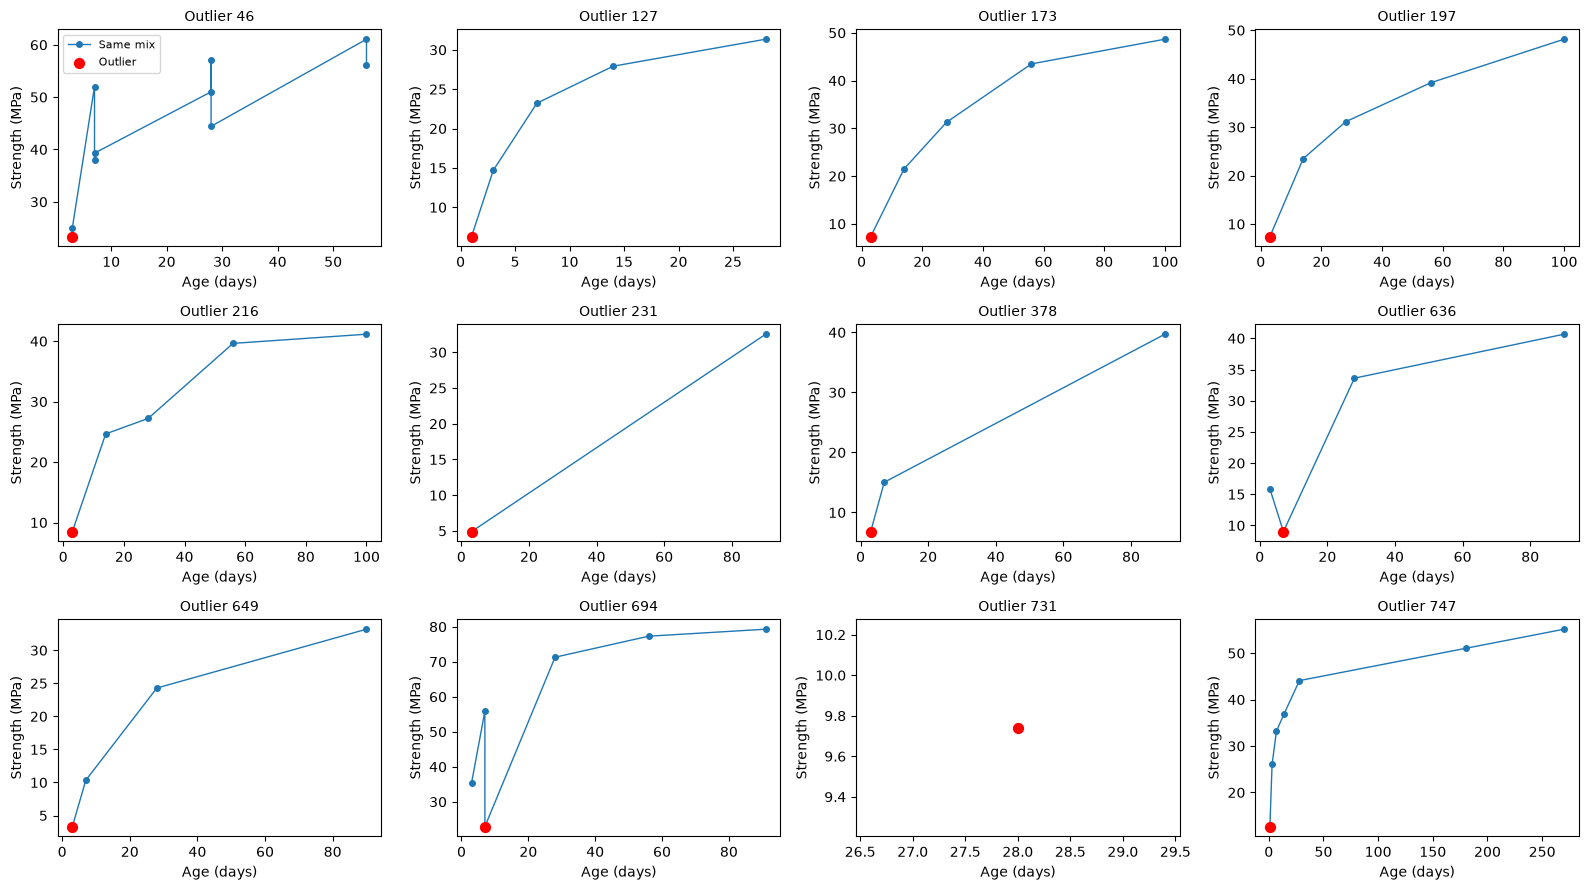

In [27]:
import math
outlier_ids = mix_groups_df.index.get_level_values("outlier").unique()
n = len(outlier_ids)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)

for ax, idx in zip(axes.flat, outlier_ids):
    group = mix_groups_df.loc[idx]   # samples with the same mix as this outlier

    ax.plot(group["age"], group[TARGET], marker="o", markersize=4, linewidth=1, label="Same mix")
    ax.scatter(group.loc[idx, "age"], group.loc[idx, TARGET], s=50, color="red", zorder=3, label="Outlier")

    ax.set_title(f"Outlier {idx}", fontsize=10)
    ax.set_xlabel("Age (days)")
    ax.set_ylabel("Strength (MPa)")

# Hide unused subplots
for ax in axes.flat[n:]:
    ax.axis("off")

axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()




De estas curvas solo se puede concluir que las muestras 636 y 694 realmente son outliers porque quiebran la curva de resistencia del concreto. Muestran una resistencia más baja que la de la misma mezcla a una edad menor.

Las curvas de las mezclas de los outliers 127, 173, 197 y 649 parecen ser las esperadas. Sin embargo, el modelo no está prediciendo correctamente las resistencia para estos puntos. 

Por otra parte los outliers 127 y 747 son las unicas muestras con edad de 1 día en el set de entrenamiento y validacion. Lo cual puede ser muy pocas  muestras para que el modelo aprenda a predecir correctamente la resistencia del concreto de un día.

Se intenta entrenar el modelo para ln(age) en vez de age directamente, dado que si la relación entre los parametros y el target es casi lineal, el modelo necesitaría aprender mucho menos.

In [28]:
train_val_clean = train_val_df.drop(index=[636, 694])

train_val_clean["ln_age"] = np.log(train_val_clean["age"])
train_val_clean = train_val_clean.drop(columns="age")

FEATURES_LOG = ["cement", "slag", "fly_ash", "water", "superplasticizer",
            "coarse_agg", "fine_agg", "ln_age"]

X = train_val_clean[FEATURES_LOG]
y = train_val_clean[TARGET]

In [29]:
comparison["selected models with data cleaned"] = evaluate_models(selected_models, X, y,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

In [30]:
t_num += 1
t_name = "Comparación de los modelos seleccionado con los datos limpiados y ln(age)."
show_table(comparison["selected models with data cleaned"], t_num, t_name, hide_index=True, precision=4)

**Table 15.** Comparación de los modelos seleccionado con los datos limpiados y ln(age).

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(256, 128, 64)",1.0000,relu,4.3173,0.6293,14.5773,5.3125,0.5055,9.5151,0.9953,1.2305,158.7000,validation (10),1.4421
"(128, 64)",0.1000,relu,4.5392,0.2378,5.2389,5.4136,0.3734,6.8968,0.8744,1.1926,288.5000,validation (10),0.8938
"(128, 64)",1.0000,relu,4.6083,0.1832,3.9755,5.4351,0.3667,6.7473,0.8268,1.1794,271.9000,validation (10),0.8690
"(128,)",1.0000,relu,5.5540,0.5373,9.6737,6.0986,0.5270,8.6414,0.5446,1.0981,541.3000,validation (10),0.6265


Para separar el efecto de cada cambio, se evalúan los mismos modelos seleccionados con: (a) los datos originales, (b) solo los datos limpiados (edad en días) y (c) solo ln(age) (sin limpiar los datos).

In [31]:
# (a) Original data with age in days
X_original = train_val_df[FEATURES]
y_original = train_val_df[TARGET]

comparison["selected models"] = evaluate_models(selected_models, X_original, y_original,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

t_num += 1
t_name = "Comparación de los modelos seleccionados con los datos originales."
show_table(comparison["selected models"], t_num, t_name, hide_index=True, precision=4)

**Table 16.** Comparación de los modelos seleccionados con los datos originales.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(256, 128, 64)",1.0000,relu,4.6081,0.8364,18.1505,5.9288,0.6450,10.8799,1.3207,1.2866,189.7000,validation (10),9.9536
"(128, 64)",1.0000,relu,5.1168,0.6415,12.5371,6.2473,0.8116,12.9913,1.1305,1.2209,304.2000,validation (10),2.8567
"(128, 64)",0.1000,relu,5.2101,0.5980,11.4774,6.2593,0.7670,12.2539,1.0492,1.2014,302.2000,validation (10),1.1020
"(128,)",1.0000,relu,6.2486,0.2586,4.1380,6.8989,0.9030,13.0884,0.6503,1.1041,589.5000,validation (10),0.7336


In [32]:
# (b) Cleaned data (without 636 and 694) with age in days
train_val_clean_age = train_val_df.drop(index=[636, 694])

X_clean_age = train_val_clean_age[FEATURES]
y_clean_age = train_val_clean_age[TARGET]

comparison["selected models with data cleaned only"] = evaluate_models(selected_models, X_clean_age, y_clean_age,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

t_num += 1
t_name = "Comparación de los modelos seleccionados con los datos limpiados (edad en días)."
show_table(comparison["selected models with data cleaned only"], t_num, t_name, hide_index=True, precision=4)

**Table 17.** Comparación de los modelos seleccionados con los datos limpiados (edad en días).

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(256, 128, 64)",1.0000,relu,4.7772,0.5104,10.6843,5.9395,0.5763,9.7022,1.1623,1.2433,167.8000,validation (10),9.0956
"(128, 64)",0.1000,relu,4.9536,0.3263,6.5874,6.1676,0.5044,8.1789,1.2140,1.2451,315.1000,validation (10),6.5925
"(128, 64)",1.0000,relu,5.0793,0.3003,5.9117,6.2039,0.4401,7.0936,1.1247,1.2214,295.9000,validation (10),4.6188
"(128,)",1.0000,relu,6.5356,0.5140,7.8648,7.2651,0.6703,9.2263,0.7295,1.1116,537.2000,validation (10),1.7640


In [33]:
# (c) Original data (with 636 and 694) with ln(age)
train_val_ln = train_val_df.copy()
train_val_ln["ln_age"] = np.log(train_val_ln["age"])
train_val_ln = train_val_ln.drop(columns="age")

X_ln = train_val_ln[FEATURES_LOG]
y_ln = train_val_ln[TARGET]

comparison["selected models with ln(age) only"] = evaluate_models(selected_models, X_ln, y_ln,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

t_num += 1
t_name = "Comparación de los modelos seleccionados con ln(age) (sin limpiar los datos)."
show_table(comparison["selected models with ln(age) only"], t_num, t_name, hide_index=True, precision=4)

**Table 18.** Comparación de los modelos seleccionados con ln(age) (sin limpiar los datos).

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(256, 128, 64)",1.0000,relu,4.2240,0.3515,8.3210,5.2618,0.6181,11.7471,1.0378,1.2457,170.6000,validation (10),8.5734
"(128, 64)",0.1000,relu,4.8779,0.3333,6.8335,5.6410,0.5625,9.9724,0.7631,1.1564,259.0000,validation (10),3.1768
"(128, 64)",1.0000,relu,4.9006,0.4160,8.4885,5.6907,0.6610,11.6156,0.7901,1.1612,252.9000,validation (10),5.4354
"(128,)",1.0000,relu,5.4595,0.3276,6.0004,6.0370,0.5973,9.8940,0.5775,1.1058,575.9000,validation (10),2.0752


In [34]:
binder = train_val_clean["cement"] + train_val_clean["slag"] + train_val_clean["fly_ash"]
train_val_clean["binder_water"] = binder / train_val_clean["water"]
train_val_clean["water_cement"] = train_val_clean["water"] / train_val_clean["cement"]

FEATURES_LOG = ["cement", "slag", "fly_ash", "water", "superplasticizer",
            "coarse_agg", "fine_agg", "ln_age"] + ["binder_water", "water_cement"]

X = train_val_clean[FEATURES_LOG]
y = train_val_clean[TARGET]

In [35]:
comparison["selected models with b/w and w/c"] = evaluate_models(selected_models, X, y,
                                         early_stopping=True,
                                         n_iter_no_change=10,
                                         validation_fraction=0.1,
                                         tol=1e-4,
                                         max_iter=2000)

In [36]:
t_num += 1
t_name = "Comparación de los modelos seleccionados con los datos limpiados, ln(age), b/w y w/c."
show_table(comparison["selected models with b/w and w/c"], t_num, t_name, hide_index=True, precision=4)

**Table 19.** Comparación de los modelos seleccionados con los datos limpiados, ln(age), b/w y w/c.

layers,alpha,activation,RMSE train,RMSE train std,CoV train (%),RMSE val,RMSE val std,CoV val (%),RMSE gap (MPa),RMSE ratio,epochs (mean),stop rule (folds),fit time (s)
"(256, 128, 64)",1.0000,relu,4.2242,0.5374,12.7229,5.2512,0.3948,7.5173,1.0270,1.2431,152.1000,validation (10),8.3713
"(128, 64)",1.0000,relu,4.9282,0.3714,7.5370,5.7330,0.4592,8.0095,0.8048,1.1633,218.3000,validation (10),4.4479
"(128, 64)",0.1000,relu,4.9519,0.2615,5.2809,5.7413,0.3682,6.4137,0.7894,1.1594,226.1000,validation (10),4.3104
"(128,)",1.0000,relu,5.4816,0.3936,7.1810,6.0819,0.4084,6.7145,0.6003,1.1095,460.8000,validation (10),1.6381


Resumen del RMSE de validación de los modelos seleccionados con cada cambio.

In [37]:
scenarios = {
    "Original": "selected models",
    "Cleaned": "selected models with data cleaned only",
    "ln(age)": "selected models with ln(age) only",
    "Cleaned + ln(age)": "selected models with data cleaned",
    "Cleaned + ln(age) + b/w + w/c": "selected models with b/w and w/c",
}

# One column per scenario, one row per model (layers and alpha)
summary = pd.DataFrame()
for name, key in scenarios.items():
    summary[name] = comparison[key].set_index(["layers", "alpha"])["RMSE val"]

t_num += 1
show_table(summary.reset_index(), t_num, "RMSE de validación (MPa) de los modelos seleccionados con cada cambio.",
           hide_index=True, precision=4)

**Table 20.** RMSE de validación (MPa) de los modelos seleccionados con cada cambio.

layers,alpha,Original,Cleaned,ln(age),Cleaned + ln(age),Cleaned + ln(age) + b/w + w/c
"(256, 128, 64)",1.0000,5.9288,5.9395,5.2618,5.3125,5.2512
"(128, 64)",1.0000,6.2473,6.2039,5.6907,5.4351,5.7330
"(128, 64)",0.1000,6.2593,6.1676,5.6410,5.4136,5.7413
"(128,)",1.0000,6.8989,7.2651,6.0370,6.0986,6.0819


## Modelo final y evaluación en el set de prueba

Se entrena el modelo seleccionado con todos los datos de entrenamiento y validación (sin los outliers 636 y 694, con ln(age), b/w y w/c). La validación cruzada solo se usó para elegir el modelo; ahora se entrena una sola vez con todos los datos.

In [38]:
# Final model (best model of the last table)
final_model = clone(model).set_params(mlp__hidden_layer_sizes=(256, 128, 64),
                                      mlp__alpha=1,
                                      mlp__activation="relu")

# Train with all the cleaned train-val data
X_train_val = train_val_clean[FEATURES_LOG]
y_train_val = train_val_clean[TARGET]
final_model.fit(X_train_val, y_train_val)

print(f"Features: {FEATURES_LOG}")
print(f"Training samples: {len(X_train_val)}")
print(f"Epochs: {final_model.named_steps['mlp'].n_iter_}")

Features: ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_agg', 'fine_agg', 'ln_age', 'binder_water', 'water_cement']
Training samples: 803
Epochs: 210


Al set de prueba se le aplican las mismas transformaciones que al de entrenamiento (ln(age), b/w y w/c). No se elimina ningún registro del set de prueba.

In [39]:
test_clean = test_df.copy()

test_clean["ln_age"] = np.log(test_clean["age"])
test_clean = test_clean.drop(columns="age")

binder_test = test_clean["cement"] + test_clean["slag"] + test_clean["fly_ash"]
test_clean["binder_water"] = binder_test / test_clean["water"]
test_clean["water_cement"] = test_clean["water"] / test_clean["cement"]

X_test = test_clean[FEATURES_LOG]
y_test = test_clean[TARGET]

print(f"test: {X_test.shape[0]} samples, {X_test.shape[1]} features")

test: 206 samples, 10 features


Se calcula el RMSE en el set de prueba y se compara con el RMSE de la validación cruzada del mismo modelo. También se calcula el R² para comparar con Yeh (1998), que obtuvo R² entre 0.81 y 0.92 en prueba.

In [40]:
# Predictions
y_pred_train = final_model.predict(X_train_val)
y_pred_test = final_model.predict(X_test)

# RMSE and R²
rmse_train = np.sqrt(((y_train_val - y_pred_train) ** 2).mean())
rmse_test = np.sqrt(((y_test - y_pred_test) ** 2).mean())
r2_test = 1 - ((y_test - y_pred_test) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()

# Cross-validation results of the same model (first row: lowest RMSE val)
cv_best = comparison["selected models with b/w and w/c"].iloc[0]

test_results = pd.DataFrame({
    "set": ["Train (all train-val)", "Validation (10-fold CV)", "Test"],
    "RMSE (MPa)": [rmse_train, cv_best["RMSE val"], rmse_test],
})

t_num += 1
show_table(test_results, t_num, "RMSE del modelo final en entrenamiento, validación cruzada y prueba.", hide_index=True)
print(f"R² test: {r2_test:.3f}")

**Table 21.** RMSE del modelo final en entrenamiento, validación cruzada y prueba.

set,RMSE (MPa)
Train (all train-val),3.23
Validation (10-fold CV),5.25
Test,4.40


R² test: 0.938


Gráfico de paridad (resistencia predicha vs. medida) y error de predicción según la edad.

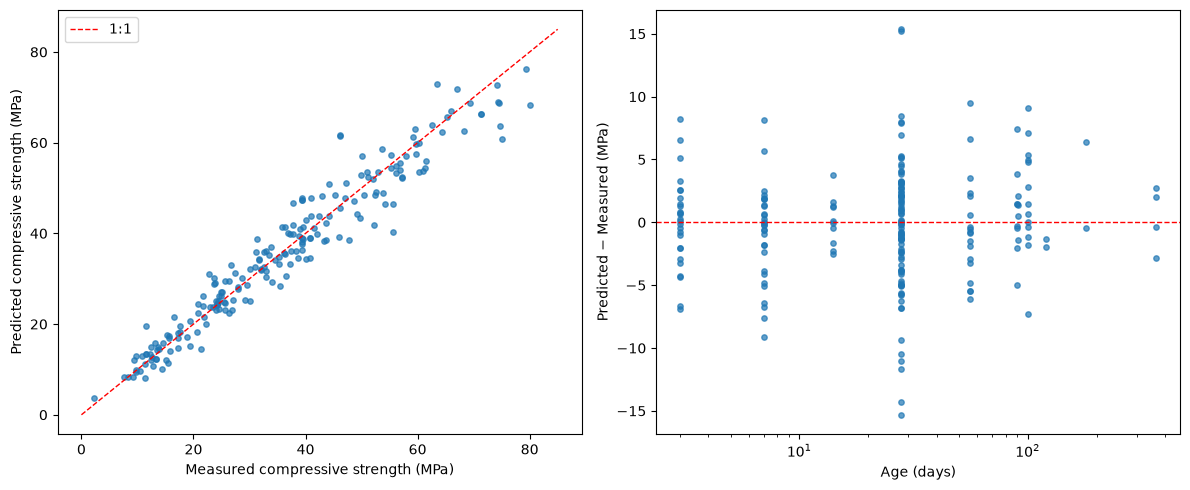

In [41]:
error_test = y_pred_test - y_test

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Predicted vs measured, with the 1:1 line
axes[0].scatter(y_test, y_pred_test, s=15, alpha=0.7)
axes[0].plot([0, 85], [0, 85], color="red", linestyle="--", linewidth=1, label="1:1")
axes[0].set_xlabel("Measured compressive strength (MPa)")
axes[0].set_ylabel("Predicted compressive strength (MPa)")
axes[0].legend()

# Error vs age
axes[1].scatter(test_df["age"], error_test, s=15, alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xscale("log")
axes[1].set_xlabel("Age (days)")
axes[1].set_ylabel("Predicted − Measured (MPa)")

plt.tight_layout()
plt.show()

Algunas muestras del set de prueba también están en el set de entrenamiento y validación. Como el modelo ya las vio al entrenar, se calcula el RMSE de prueba sin ellas para verificar si mejoran el resultado.

In [42]:
# Test samples that are also in train-val (same 8 features and strength)
train_val_rows = train_val_df.apply(tuple, axis=1)
in_train_val = test_df.apply(tuple, axis=1).isin(train_val_rows)

rmse_test_new = np.sqrt(((y_test[~in_train_val] - y_pred_test[~in_train_val]) ** 2).mean())

overlap_results = pd.DataFrame({
    "test samples": ["All", "Without samples in train-val"],
    "n samples": [len(y_test), (~in_train_val).sum()],
    "RMSE (MPa)": [rmse_test, rmse_test_new],
})

t_num += 1
show_table(overlap_results, t_num, "RMSE de prueba con y sin las muestras que también están en train-val.", hide_index=True)

**Table 22.** RMSE de prueba con y sin las muestras que también están en train-val.

test samples,n samples,RMSE (MPa)
All,206,4.40
Without samples in train-val,200,4.42


Se verifica la predicción de la muestra del set de prueba que tiene features fuera del rango del set de entrenamiento y validación (extrapolación).

In [43]:
outside_results = samples_outside.assign(predicted=y_pred_test[filtered],
                                         error=error_test[filtered])

t_num += 1
show_table(outside_results, t_num, "Predicción de la muestra de prueba fuera del rango de train-val.", hide_index=False)

**Table 23.** Predicción de la muestra de prueba fuera del rango de train-val.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,predicted,error
18,237.00,92.00,71.00,247.00,6.00,853.00,695.00,28,28.63,30.11,1.48
